In [12]:
!pip install -q ultralytics pyyaml pandas

import os, torch
PROJECT = "/content/industrial-safety-monitoring"   # use "/content/drive/MyDrive/..." after mounting Drive to keep files
os.makedirs(PROJECT, exist_ok=True)
%cd {PROJECT}
!mkdir -p config models detection compliance alerts utils scripts uploads outputs/images outputs/videos outputs/violations
!touch config/__init__.py detection/__init__.py compliance/__init__.py alerts/__init__.py utils/__init__.py
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

/content/industrial-safety-monitoring
CUDA: True Tesla T4


In [13]:
%%writefile config/settings.py
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent.parent
MODELS_DIR = BASE_DIR / "models"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_IMAGES_DIR = OUTPUT_DIR / "images"
OUTPUT_VIDEOS_DIR = OUTPUT_DIR / "videos"
OUTPUT_VIOLATIONS_DIR = OUTPUT_DIR / "violations"

CUSTOM_MODEL_PATH = MODELS_DIR / "best.pt"
PRETRAINED_MODEL_NAME = "yolo11n.pt"
PRETRAINED_MODEL_PATH = MODELS_DIR / PRETRAINED_MODEL_NAME

DEFAULT_CONFIDENCE = 0.40
IOU_THRESHOLD = 0.45
IMAGE_SIZE = 640

CLASS_PERSON = "person"
CLASS_HELMET = "helmet"
CLASS_VEST = "safety_vest"
REQUIRED_CLASSES = (CLASS_PERSON, CLASS_HELMET, CLASS_VEST)

# Dataset class names (lower-cased, spaces/hyphens -> underscores) -> our names.
# Anything not listed (e.g. "no_hardhat") is ignored.
CLASS_ALIASES = {
    "person": CLASS_PERSON, "worker": CLASS_PERSON,
    "helmet": CLASS_HELMET, "hardhat": CLASS_HELMET, "hard_hat": CLASS_HELMET,
    "safety_helmet": CLASS_HELMET,
    "safety_vest": CLASS_VEST, "vest": CLASS_VEST, "safety_jacket": CLASS_VEST,
}

CLASS_COLORS = {                       # BGR
    CLASS_PERSON: (255, 144, 30),
    CLASS_HELMET: (255, 200, 0),
    CLASS_VEST: (0, 165, 255),
}

# ---- Compliance rules (fractions of the person box height, measured from the top) ----
HELMET_ZONE = (0.0, 0.40)      # helmet center must lie in the head region
VEST_ZONE = (0.15, 0.80)       # vest center must lie in the torso region
MIN_INSIDE_FRACTION = 0.5      # at least 50% of the PPE box must be inside the person box
MIN_PERSON_HEIGHT_PX = 60      # smaller persons are too tiny to judge
EDGE_MARGIN_PX = 3
OCCLUSION_IOU = 0.35           # person-person overlap that makes association unreliable

# ---- Alerts ----
ALERT_MATCH_IOU = 0.30         # same violator if boxes overlap this much between frames
ALERT_TIMEOUT_SECONDS = 3.0    # violation must disappear this long before a new alert can fire

Overwriting config/settings.py


In [14]:
%%writefile utils/geometry.py
def box_area(b):
    return max(0, b[2] - b[0]) * max(0, b[3] - b[1])

def intersection(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    return max(0, x2 - x1) * max(0, y2 - y1)

def iou(a, b):
    inter = intersection(a, b)
    union = box_area(a) + box_area(b) - inter
    return inter / union if union > 0 else 0.0

Writing utils/geometry.py


In [15]:
%%writefile utils/file_handler.py
import shutil
import subprocess
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}
VIDEO_EXTS = {".mp4", ".avi", ".mov"}
MAX_IMAGE_MB = 25
MAX_VIDEO_MB = 500


class InvalidInputError(Exception):
    """Raised for unsupported, missing, empty or corrupt input files."""


def media_type(path) -> str:
    ext = Path(path).suffix.lower()
    if ext in IMAGE_EXTS:
        return "image"
    if ext in VIDEO_EXTS:
        return "video"
    raise InvalidInputError(
        f"Unsupported file type '{ext}'. Allowed: {sorted(IMAGE_EXTS | VIDEO_EXTS)}")


def _check_file(path: Path, max_mb: int) -> None:
    if not path.is_file():
        raise InvalidInputError(f"File not found: {path}")
    size_mb = path.stat().st_size / 1e6
    if size_mb == 0:
        raise InvalidInputError(f"File is empty: {path.name}")
    if size_mb > max_mb:
        raise InvalidInputError(f"{path.name} is {size_mb:.0f} MB (limit {max_mb} MB).")


def load_image(path) -> np.ndarray:
    path = Path(path)
    if media_type(path) != "image":
        raise InvalidInputError(f"{path.name} is not an image.")
    _check_file(path, MAX_IMAGE_MB)
    image = cv2.imread(str(path))
    if image is None:
        raise InvalidInputError(f"Could not decode image (corrupt file?): {path.name}")
    return image


def open_video(path) -> cv2.VideoCapture:
    """Return an opened, validated VideoCapture. Caller must release() it."""
    path = Path(path)
    if media_type(path) != "video":
        raise InvalidInputError(f"{path.name} is not a video.")
    _check_file(path, MAX_VIDEO_MB)
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        cap.release()
        raise InvalidInputError(f"OpenCV cannot open video: {path.name}")
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if w <= 0 or h <= 0:
        cap.release()
        raise InvalidInputError(f"Video has invalid dimensions: {path.name}")
    return cap


def unique_output_path(directory: Path, stem: str, suffix: str) -> Path:
    directory.mkdir(parents=True, exist_ok=True)
    return directory / f"{stem}_{datetime.now():%Y%m%d_%H%M%S}{suffix}"


def reencode_h264(src: Path, dst: Path) -> bool:
    """OpenCV writes mp4v, which browsers can't play. Convert to H.264 with ffmpeg."""
    if shutil.which("ffmpeg") is None:
        return False
    cmd = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(src),
           "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(dst)]
    try:
        return subprocess.run(cmd, check=False).returncode == 0 and dst.is_file()
    except OSError:
        return False

Overwriting utils/file_handler.py


In [16]:
%%writefile detection/detector.py
from __future__ import annotations

import logging
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import torch
from ultralytics import YOLO

from config import settings

logger = logging.getLogger(__name__)


class ModelLoadError(Exception):
    pass


@dataclass(frozen=True)
class Detection:
    class_name: str
    confidence: float
    x1: float
    y1: float
    x2: float
    y2: float

    @property
    def width(self): return self.x2 - self.x1
    @property
    def height(self): return self.y2 - self.y1
    @property
    def area(self): return max(0.0, self.width) * max(0.0, self.height)
    @property
    def center(self): return ((self.x1 + self.x2) / 2.0, (self.y1 + self.y2) / 2.0)
    @property
    def box(self) -> Tuple[int, int, int, int]:
        return int(self.x1), int(self.y1), int(self.x2), int(self.y2)


def normalize_class_name(raw: str) -> Optional[str]:
    key = raw.strip().lower().replace("-", "_").replace(" ", "_")
    return settings.CLASS_ALIASES.get(key)


class PPEDetector:
    def __init__(self, model_path: Optional[Path] = None,
                 confidence: float = settings.DEFAULT_CONFIDENCE,
                 iou: float = settings.IOU_THRESHOLD,
                 image_size: int = settings.IMAGE_SIZE,
                 device: Optional[str] = None) -> None:
        self.confidence, self.iou, self.image_size = confidence, iou, image_size
        self.device = device or ("cuda:0" if torch.cuda.is_available() else "cpu")
        self.model_path, self.using_fallback = self._resolve(model_path)
        settings.MODELS_DIR.mkdir(parents=True, exist_ok=True)
        try:
            self.model = YOLO(str(self.model_path))
        except Exception as exc:
            raise ModelLoadError(f"Could not load model '{self.model_path}': {exc}") from exc
        self._class_map: Dict[int, Optional[str]] = {
            i: normalize_class_name(n) for i, n in self.model.names.items()}

    @staticmethod
    def _resolve(model_path):
        if model_path is not None:
            p = Path(model_path)
            if not p.is_file():
                raise ModelLoadError(f"Model file not found: {p}")
            return p, False
        if settings.CUSTOM_MODEL_PATH.is_file():
            return settings.CUSTOM_MODEL_PATH, False
        logger.warning("models/best.pt not found: using %s (person only).",
                       settings.PRETRAINED_MODEL_NAME)
        return settings.PRETRAINED_MODEL_PATH, True

    @property
    def supported_classes(self) -> set:
        return {n for n in self._class_map.values() if n is not None}

    @property
    def is_ppe_model(self) -> bool:
        return set(settings.REQUIRED_CLASSES) <= self.supported_classes

    def warmup(self) -> None:
        self.detect(np.zeros((self.image_size, self.image_size, 3), dtype=np.uint8))

    def detect(self, frame: np.ndarray, confidence: Optional[float] = None) -> List[Detection]:
        if frame is None or frame.ndim != 3:
            raise ValueError("detect() expects a color image of shape (H, W, 3).")
        conf = self.confidence if confidence is None else confidence
        result = self.model.predict(source=frame, conf=conf, iou=self.iou,
                                    imgsz=self.image_size, device=self.device, verbose=False)[0]
        if result.boxes is None or len(result.boxes) == 0:
            return []
        xyxy = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        ids = result.boxes.cls.cpu().numpy().astype(int)
        out = []
        for (x1, y1, x2, y2), s, cid in zip(xyxy, scores, ids):
            name = self._class_map.get(int(cid))
            if name is not None:
                out.append(Detection(name, float(s), float(x1), float(y1), float(x2), float(y2)))
        return out

    @staticmethod
    def count_by_class(dets: List[Detection]) -> Dict[str, int]:
        counts = {n: 0 for n in settings.REQUIRED_CLASSES}
        for d in dets:
            counts[d.class_name] = counts.get(d.class_name, 0) + 1
        return counts

Overwriting detection/detector.py


In [17]:
%%writefile compliance/ppe_checker.py
from dataclasses import dataclass, field
from typing import Callable, Dict, List, Optional

from config import settings
from detection.detector import Detection
from utils.geometry import box_area, intersection, iou

COMPLIANT = "COMPLIANT"
NON_COMPLIANT = "NON-COMPLIANT"
UNCERTAIN = "UNCERTAIN"


@dataclass
class WorkerStatus:
    person: Detection
    status: str
    helmet: Optional[Detection] = None
    vest: Optional[Detection] = None
    missing_items: List[str] = field(default_factory=list)   # e.g. ["HELMET", "VEST"]
    reason: str = ""


def _score(person: Detection, item: Detection, zone) -> float:
    """How well does `item` fit the expected body zone of `person`? 0 = not associated."""
    p, b = person.box, item.box
    if box_area(b) <= 0 or person.height <= 0 or person.width <= 0:
        return 0.0
    cx, cy = item.center
    if not (p[0] <= cx <= p[2]):
        return 0.0
    lo = p[1] + zone[0] * person.height
    hi = p[1] + zone[1] * person.height
    if not (lo <= cy <= hi):
        return 0.0
    inside = intersection(p, b) / box_area(b)
    if inside < settings.MIN_INSIDE_FRACTION:
        return 0.0
    offset = abs(cx - person.center[0]) / (person.width / 2 + 1e-6)
    return inside * (1.0 - 0.5 * min(offset, 1.0))


def _assign(persons: List[Detection], items: List[Detection], zone) -> Dict[int, Detection]:
    """Greedy one-to-one matching: best (person, item) pairs first, no item used twice."""
    pairs = []
    for pi, p in enumerate(persons):
        for ii, it in enumerate(items):
            s = _score(p, it, zone)
            if s > 0:
                pairs.append((s, pi, ii))
    pairs.sort(reverse=True)
    used_p, used_i, result = set(), set(), {}
    for _, pi, ii in pairs:
        if pi in used_p or ii in used_i:
            continue
        result[pi] = items[ii]
        used_p.add(pi)
        used_i.add(ii)
    return result


class PPEChecker:
    def __init__(self, ppe_capable: bool = True) -> None:
        # False when the loaded model has no helmet/vest classes -> never raise violations.
        self.ppe_capable = ppe_capable

    def check(self, detections: List[Detection], img_w: int, img_h: int) -> List[WorkerStatus]:
        persons = [d for d in detections if d.class_name == settings.CLASS_PERSON]
        helmets = [d for d in detections if d.class_name == settings.CLASS_HELMET]
        vests = [d for d in detections if d.class_name == settings.CLASS_VEST]

        if not self.ppe_capable:
            return [WorkerStatus(p, UNCERTAIN, reason="model has no helmet/vest classes")
                    for p in persons]

        helmet_of = _assign(persons, helmets, settings.HELMET_ZONE)
        vest_of = _assign(persons, vests, settings.VEST_ZONE)

        statuses = []
        for i, person in enumerate(persons):
            helmet, vest = helmet_of.get(i), vest_of.get(i)
            missing = []
            if helmet is None:
                missing.append("HELMET")
            if vest is None:
                missing.append("VEST")

            if not missing:
                statuses.append(WorkerStatus(person, COMPLIANT, helmet, vest))
                continue

            doubts = self._doubts(person, persons[:i] + persons[i + 1:], img_w, img_h)
            if doubts:
                statuses.append(WorkerStatus(person, UNCERTAIN, helmet, vest, missing,
                                             "; ".join(doubts)))
            else:
                statuses.append(WorkerStatus(person, NON_COMPLIANT, helmet, vest, missing,
                                             "missing " + ", ".join(missing).lower()))
        return statuses

    @staticmethod
    def _doubts(person: Detection, others: List[Detection], w: int, h: int) -> List[str]:
        """Reasons why a 'missing PPE' verdict for this person can't be trusted."""
        m, reasons = settings.EDGE_MARGIN_PX, []
        if person.height < settings.MIN_PERSON_HEIGHT_PX:
            reasons.append("person too small")
        # Bottom edge is ignored on purpose: cut-off feet don't hide a helmet or vest.
        if person.y1 <= m or person.x1 <= m or person.x2 >= w - m:
            reasons.append("person partly outside frame")
        if any(iou(person.box, o.box) > settings.OCCLUSION_IOU for o in others):
            reasons.append("overlaps another person")
        return reasons


def summarize(statuses: List[WorkerStatus]) -> Dict[str, int]:
    return {
        "workers": len(statuses),
        COMPLIANT: sum(s.status == COMPLIANT for s in statuses),
        NON_COMPLIANT: sum(s.status == NON_COMPLIANT for s in statuses),
        UNCERTAIN: sum(s.status == UNCERTAIN for s in statuses),
    }

Overwriting compliance/ppe_checker.py


In [18]:
%%writefile alerts/alert_manager.py
import csv
import logging
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path
from typing import Dict, List, Optional

import cv2

from compliance.ppe_checker import NON_COMPLIANT, WorkerStatus
from config import settings
from utils.geometry import iou

logger = logging.getLogger(__name__)


@dataclass
class ActiveAlert:
    alert_id: int
    box: tuple
    last_seen: float


class AlertManager:
    """Creates ONE alert per ongoing violation instead of one per frame.

    Violators are matched between frames by box overlap (IoU). A violation that keeps
    overlapping its previous box stays the same alert. If it disappears for longer than
    ALERT_TIMEOUT_SECONDS, a later reappearance counts as a new alert.
    """

    def __init__(self, source_name: str = "session",
                 output_dir: Path = settings.OUTPUT_VIOLATIONS_DIR) -> None:
        self.source_name = source_name
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(parents=True, exist_ok=True)
        self.active: Dict[int, ActiveAlert] = {}
        self.records: List[dict] = []
        self._next_id = 1

    def update(self, statuses: List[WorkerStatus], annotated_frame, now: float,
               frame_index: Optional[int] = None) -> List[dict]:
        """`now` = media time in seconds (frame_index / fps for video). Returns NEW alerts."""
        for aid in [a for a, al in self.active.items()
                    if now - al.last_seen > settings.ALERT_TIMEOUT_SECONDS]:
            del self.active[aid]

        new_alerts = []
        for ws in statuses:
            if ws.status != NON_COMPLIANT:
                continue
            box = ws.person.box
            best_id, best_iou = None, 0.0
            for aid, al in self.active.items():
                v = iou(box, al.box)
                if v > best_iou:
                    best_id, best_iou = aid, v

            if best_id is not None and best_iou >= settings.ALERT_MATCH_IOU:
                self.active[best_id].box = box          # same ongoing violation
                self.active[best_id].last_seen = now
                continue

            alert_id = self._next_id
            self._next_id += 1
            self.active[alert_id] = ActiveAlert(alert_id, box, now)
            wall = datetime.now()
            snap = self.output_dir / f"{self.source_name}_alert{alert_id:03d}_{wall:%H%M%S}.jpg"
            cv2.imwrite(str(snap), annotated_frame)
            record = {
                "alert_id": alert_id,
                "timestamp": wall.isoformat(timespec="seconds"),
                "media_time_s": round(now, 2),
                "frame": frame_index if frame_index is not None else "",
                "missing": ", ".join(ws.missing_items),
                "person_confidence": round(ws.person.confidence, 3),
                "snapshot": str(snap),
            }
            self.records.append(record)
            new_alerts.append(record)
            logger.info("ALERT #%d at %.1fs: missing %s", alert_id, now, record["missing"])
        return new_alerts

    def save_csv(self) -> Optional[Path]:
        if not self.records:
            return None
        path = self.output_dir / f"{self.source_name}_violations.csv"
        with open(path, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=list(self.records[0].keys()))
            writer.writeheader()
            writer.writerows(self.records)
        return path

Overwriting alerts/alert_manager.py


In [19]:
%%writefile utils/drawing.py
import cv2

from compliance.ppe_checker import COMPLIANT, NON_COMPLIANT, UNCERTAIN, summarize
from config import settings

FONT = cv2.FONT_HERSHEY_SIMPLEX
STATUS_COLORS = {COMPLIANT: (0, 170, 0), NON_COMPLIANT: (0, 0, 255), UNCERTAIN: (0, 200, 255)}


def _label(img, text, x, y, bg, fg, scale, thick):
    (tw, th), base = cv2.getTextSize(text, FONT, scale, thick)
    top = y - th - base - 4
    if top < 0:
        top = y
    cv2.rectangle(img, (x, top), (x + tw + 6, top + th + base + 4), bg, -1)
    cv2.putText(img, text, (x + 3, top + th + 1), FONT, scale, fg, thick, cv2.LINE_AA)


def draw_results(frame, detections, statuses, ppe_capable=True):
    """Draw PPE boxes, colored worker boxes and a summary banner on `frame` (in place)."""
    scale = max(0.45, min(frame.shape[:2]) / 900)       # adapts to any resolution
    thick = max(1, round(scale * 2))
    box_t = max(2, round(scale * 3))

    for d in detections:
        if d.class_name == settings.CLASS_PERSON:
            continue
        x1, y1, x2, y2 = d.box
        color = settings.CLASS_COLORS.get(d.class_name, (0, 255, 0))
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, max(1, box_t - 1))
        _label(frame, f"{d.class_name} {d.confidence:.2f}", x1, y2 + int(18 * scale * 1.5),
               color, (0, 0, 0), scale * 0.8, thick)

    for ws in statuses:
        x1, y1, x2, y2 = ws.person.box
        color = STATUS_COLORS[ws.status]
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, box_t + (1 if ws.status == NON_COMPLIANT else 0))
        if ws.status == NON_COMPLIANT:
            text = "VIOLATION: " + ", ".join("NO " + m for m in ws.missing_items)
            fg = (255, 255, 255)
        elif ws.status == UNCERTAIN:
            text = "UNCERTAIN"
            fg = (0, 0, 0)
        else:
            text = f"OK {ws.person.confidence:.2f}"
            fg = (255, 255, 255)
        _label(frame, text, x1, y1, color, fg, scale, thick)

    s = summarize(statuses)
    if not ppe_capable:
        banner, bg = f"Workers: {s['workers']} | PPE model not loaded (person detection only)", (80, 80, 80)
    else:
        banner = (f"Workers: {s['workers']} | OK: {s[COMPLIANT]} | "
                  f"VIOLATIONS: {s[NON_COMPLIANT]} | Uncertain: {s[UNCERTAIN]}")
        bg = (0, 0, 200) if s[NON_COMPLIANT] else (50, 50, 50)
    _label(frame, banner, 0, int(34 * scale), bg, (255, 255, 255), scale, thick)
    return frame

Overwriting utils/drawing.py


In [20]:
%%writefile detection/image_processor.py
from dataclasses import dataclass
from pathlib import Path
from typing import List, Optional

import cv2
import numpy as np

from alerts.alert_manager import AlertManager
from compliance.ppe_checker import PPEChecker, WorkerStatus, summarize
from config import settings
from detection.detector import Detection, PPEDetector
from utils.drawing import draw_results
from utils.file_handler import load_image, unique_output_path


@dataclass
class FrameResult:
    annotated: np.ndarray
    detections: List[Detection]
    statuses: List[WorkerStatus]
    new_alerts: List[dict]


def analyze_frame(frame, detector: PPEDetector, checker: PPEChecker,
                  alerts: Optional[AlertManager], conf: float,
                  now: float = 0.0, frame_index: Optional[int] = None) -> FrameResult:
    """detect -> check compliance -> draw -> alerts. Shared by images and video."""
    h, w = frame.shape[:2]
    detections = detector.detect(frame, confidence=conf)
    statuses = checker.check(detections, w, h)
    annotated = draw_results(frame.copy(), detections, statuses, checker.ppe_capable)
    new_alerts = alerts.update(statuses, annotated, now, frame_index) if alerts else []
    return FrameResult(annotated, detections, statuses, new_alerts)


def process_image(path, detector: PPEDetector, checker: PPEChecker,
                  conf: float = settings.DEFAULT_CONFIDENCE) -> dict:
    image = load_image(path)
    stem = Path(path).stem
    alerts = AlertManager(source_name=stem)
    result = analyze_frame(image, detector, checker, alerts, conf)

    out_path = unique_output_path(settings.OUTPUT_IMAGES_DIR, f"{stem}_annotated", ".jpg")
    if not cv2.imwrite(str(out_path), result.annotated):
        raise IOError(f"Could not write {out_path}")
    csv_path = alerts.save_csv()

    return {
        "output_path": out_path,
        "counts": detector.count_by_class(result.detections),
        "compliance": summarize(result.statuses),
        "workers": result.statuses,
        "alerts": result.new_alerts,
        "csv_path": csv_path,
    }

Overwriting detection/image_processor.py


In [21]:
%%writefile detection/video_processor.py
import time
from pathlib import Path
from typing import Callable, Optional

import cv2

from alerts.alert_manager import AlertManager
from compliance.ppe_checker import NON_COMPLIANT, PPEChecker
from config import settings
from detection.detector import PPEDetector
from detection.image_processor import analyze_frame
from utils.drawing import draw_results
from utils.file_handler import open_video, reencode_h264, unique_output_path


def process_video(path, detector: PPEDetector, checker: PPEChecker,
                  conf: float = settings.DEFAULT_CONFIDENCE, frame_stride: int = 1,
                  progress_cb: Optional[Callable[[int, int], None]] = None) -> dict:
    """frame_stride=2 runs the model on every 2nd frame (faster); skipped frames reuse
    the previous boxes. Output keeps the original resolution and frame rate."""
    cap = open_video(path)
    writer = None
    raw_path = None
    try:
        fps = cap.get(cv2.CAP_PROP_FPS)
        if not fps or fps != fps or fps <= 0 or fps > 240:   # 0, NaN or nonsense -> default
            fps = 25.0
        w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        stem = Path(path).stem
        alerts = AlertManager(source_name=stem)
        raw_path = unique_output_path(settings.OUTPUT_VIDEOS_DIR, f"{stem}_raw", ".mp4")
        writer = cv2.VideoWriter(str(raw_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
        if not writer.isOpened():
            raise IOError("Could not create the output video file.")

        stride = max(1, int(frame_stride))
        idx = processed = violation_frames = max_workers = 0
        last = None
        t0 = time.perf_counter()

        while True:
            ok, frame = cap.read()
            if not ok:
                break
            if frame.shape[1] != w or frame.shape[0] != h:
                frame = cv2.resize(frame, (w, h))

            if last is None or idx % stride == 0:
                last = analyze_frame(frame, detector, checker, alerts, conf,
                                     now=idx / fps, frame_index=idx)
                out_frame = last.annotated
                processed += 1
                max_workers = max(max_workers, len(last.statuses))
                if any(s.status == NON_COMPLIANT for s in last.statuses):
                    violation_frames += 1
            else:
                out_frame = draw_results(frame.copy(), last.detections, last.statuses,
                                         checker.ppe_capable)
            writer.write(out_frame)
            idx += 1
            if progress_cb:
                progress_cb(idx, total)
    finally:
        cap.release()
        if writer is not None:
            writer.release()

    elapsed = max(time.perf_counter() - t0, 1e-6)
    final_path = raw_path.with_name(raw_path.name.replace("_raw_", "_annotated_"))
    if reencode_h264(raw_path, final_path):
        raw_path.unlink(missing_ok=True)       # temp file cleanup
    else:
        raw_path.rename(final_path)            # fallback: mp4v (may not play in browser)

    return {
        "output_path": final_path,
        "frames_read": idx,
        "frames_inferred": processed,
        "resolution": f"{w}x{h}",
        "video_fps": round(fps, 2),
        "processing_fps": round(idx / elapsed, 1),
        "seconds": round(elapsed, 1),
        "max_workers_in_frame": max_workers,
        "frames_with_violation": violation_frames,
        "unique_alerts": len(alerts.records),
        "alerts": alerts.records,
        "csv_path": alerts.save_csv(),
    }

Overwriting detection/video_processor.py



Device : cuda:0
Model  : yolo11n.pt
Classes: ['person']

Upload your image(s) / video(s):


Saving images.jpeg to images.jpeg

Processing: images.jpeg
Detected objects : {'person': 4, 'helmet': 0, 'safety_vest': 0}
Compliance       : {'workers': 4, 'COMPLIANT': 0, 'NON-COMPLIANT': 0, 'UNCERTAIN': 4}
  Worker 1: UNCERTAIN      model has no helmet/vest classes
  Worker 2: UNCERTAIN      model has no helmet/vest classes
  Worker 3: UNCERTAIN      model has no helmet/vest classes
  Worker 4: UNCERTAIN      model has no helmet/vest classes
Alerts raised    : 0 | log: None


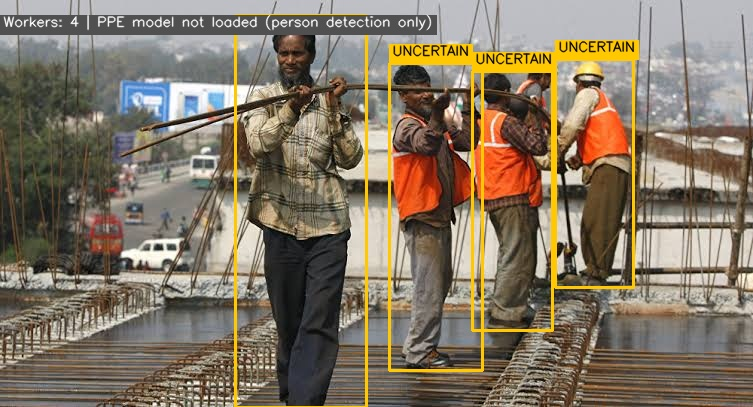

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import sys, os, shutil, logging
from base64 import b64encode
from pathlib import Path

os.chdir(PROJECT)
sys.path.insert(0, PROJECT)
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")

from google.colab import files
from IPython.display import Image as IPImage, HTML, display
from tqdm.auto import tqdm

from config import settings
from detection.detector import PPEDetector, ModelLoadError
from compliance.ppe_checker import PPEChecker
from detection.image_processor import process_image
from detection.video_processor import process_video
from utils.file_handler import media_type, InvalidInputError

CONF = 0.40          # confidence threshold (0.1 - 0.9)
FRAME_STRIDE = 1     # 2 or 3 = faster video, less precise

try:
    detector = PPEDetector(confidence=CONF)
except ModelLoadError as e:
    raise SystemExit(f"Model error: {e}")
detector.warmup()
checker = PPEChecker(ppe_capable=detector.is_ppe_model)

print(f"\nDevice : {detector.device}\nModel  : {detector.model_path.name}\nClasses: {sorted(detector.supported_classes)}")
if not detector.is_ppe_model:
    print("WARNING: this model cannot detect helmets/vests. Workers will show UNCERTAIN. Train a PPE model (Cell 11).")

def show_video(path, width=700):
    data = Path(path).read_bytes()
    if len(data) > 40e6:
        print("Video too large to embed, use the download below."); return
    b64 = b64encode(data).decode()
    display(HTML(f'<video width="{width}" controls><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))

print("\nUpload your image(s) / video(s):")
uploaded = files.upload()

for name in uploaded:
    src = Path(PROJECT) / "uploads" / name
    shutil.move(name, src)
    print("\n" + "=" * 60 + f"\nProcessing: {name}\n" + "=" * 60)
    try:
        kind = media_type(src)
        if kind == "image":
            r = process_image(src, detector, checker, CONF)
            print("Detected objects :", r["counts"])
            print("Compliance       :", r["compliance"])
            for i, w in enumerate(r["workers"], 1):
                print(f"  Worker {i}: {w.status:<14} {w.reason}")
            print("Alerts raised    :", len(r["alerts"]), "| log:", r["csv_path"])
            display(IPImage(str(r["output_path"])))
            files.download(str(r["output_path"]))
        else:
            bar = tqdm(total=None, desc="Frames")
            def cb(done, total):
                if bar.total != total: bar.total = total
                bar.n = done; bar.refresh()
            r = process_video(src, detector, checker, CONF, FRAME_STRIDE, cb)
            bar.close()
            print({k: v for k, v in r.items() if k not in ("alerts", "output_path")})
            print("Output:", r["output_path"])
            show_video(r["output_path"])
            files.download(str(r["output_path"]))
    except InvalidInputError as e:
        print("Invalid file:", e)
    except Exception as e:
        print("Error:", type(e).__name__, e)

In [39]:
import os, sys, shutil, zipfile, random, yaml
from pathlib import Path
from google.colab import files

os.chdir(PROJECT)
sys.path.insert(0, PROJECT)
from detection.detector import normalize_class_name
from config import settings

FINAL_CLASSES = list(settings.REQUIRED_CLASSES)      # ['person', 'helmet', 'safety_vest']
RAW = Path("/content/raw_datasets"); RAW.mkdir(exist_ok=True)
OUT = Path("/content/ppe_merged")
IMG_EXT = {".jpg", ".jpeg", ".png"}

# ---------- 1. Upload one or more dataset zips ----------
print("Select your dataset zip file(s):")
uploaded = files.upload()
for name in uploaded:
    if name.lower().endswith(".zip"):
        dest = RAW / Path(name).stem
        dest.mkdir(exist_ok=True)
        with zipfile.ZipFile(name) as z:
            z.extractall(dest)
        os.remove(name)
    else:
        print("Skipped (not a zip):", name)

# ---------- 2. Merge into one dataset with unified class IDs ----------
if OUT.exists():
    shutil.rmtree(OUT)
for s in ("train", "val", "test"):
    (OUT / s / "images").mkdir(parents=True)
    (OUT / s / "labels").mkdir(parents=True)

SPLIT_NAMES = {"train": "train", "valid": "val", "val": "val", "validation": "val", "test": "test"}
rng = random.Random(42)
box_counts = {c: 0 for c in FINAL_CLASSES}
dropped = n_images = 0

yamls = sorted(RAW.rglob("data.yaml"))
if not yamls:
    raise SystemExit("No data.yaml found in the uploaded zips. Each dataset needs one.")

for di, ypath in enumerate(yamls):
    root = ypath.parent
    cfg = yaml.safe_load(open(ypath))
    names = cfg["names"]
    names = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)

    idmap = {}
    for i, n in enumerate(names):
        mapped = normalize_class_name(str(n))
        idmap[i] = FINAL_CLASSES.index(mapped) if mapped else None
    print(f"\nDataset {di} ({root.name})")
    for i, n in enumerate(names):
        target = FINAL_CLASSES[idmap[i]] if idmap[i] is not None else "IGNORED"
        print(f"   {n!r:<20} -> {target}")

    for img_dir in sorted(root.rglob("images")):
        lbl_dir = img_dir.parent / "labels"
        if not img_dir.is_dir() or not lbl_dir.is_dir():
            continue
        fixed_split = SPLIT_NAMES.get(img_dir.parent.name.lower())

        for img in img_dir.iterdir():
            if img.suffix.lower() not in IMG_EXT:
                continue
            lines_out = []
            lbl = lbl_dir / (img.stem + ".txt")
            if lbl.exists():
                for ln in lbl.read_text().splitlines():
                    parts = ln.split()
                    if len(parts) < 5:
                        continue
                    new_id = idmap.get(int(float(parts[0])))
                    if new_id is None:
                        dropped += 1
                        continue
                    lines_out.append(" ".join([str(new_id)] + parts[1:]))
                    box_counts[FINAL_CLASSES[new_id]] += 1

            split = fixed_split or ("val" if rng.random() < 0.15 else "train")
            stem = f"d{di}_{img.stem}"
            shutil.copy(img, OUT / split / "images" / (stem + img.suffix))
            (OUT / split / "labels" / (stem + ".txt")).write_text("\n".join(lines_out))
            n_images += 1

# make sure a validation set exists
val_imgs = list((OUT / "val" / "images").iterdir())
if not val_imgs:
    train_imgs = list((OUT / "train" / "images").iterdir())
    rng.shuffle(train_imgs)
    for img in train_imgs[: max(1, int(0.15 * len(train_imgs)))]:
        lbl = OUT / "train" / "labels" / (img.stem + ".txt")
        shutil.move(str(img), OUT / "val" / "images" / img.name)
        if lbl.exists():
            shutil.move(str(lbl), OUT / "val" / "labels" / lbl.name)

split_sizes = {s: len(list((OUT / s / "images").iterdir())) for s in ("train", "val", "test")}
print("\n==== MERGED DATASET ====")
print("Images per split :", split_sizes)
print("Boxes per class  :", box_counts)
print("Boxes ignored    :", dropped, "(classes like no_helmet that the app does not use)")

data = {
    "path": str(OUT),
    "train": "train/images",
    "val": "val/images",
    "names": {i: n for i, n in enumerate(FINAL_CLASSES)},
}
if split_sizes["test"] > 0:
    data["test"] = "test/images"
yaml_path = str(OUT / "data.yaml")          # Cell 12 (evaluation) reuses this variable
yaml.safe_dump(data, open(yaml_path, "w"))

# ---------- 3. Train only if every class has examples ----------
empty = [c for c, n in box_counts.items() if n == 0]
if empty:
    print(f"\nSTOP: no training boxes for {empty}. Send me the 'Dataset ... ->' lines above.")
else:
    from ultralytics import YOLO
    model = YOLO("yolo11s.pt")
    model.train(
        data=yaml_path,
        epochs=50,
        imgsz=640,
        batch=16,            # use 8 if you get CUDA out of memory
        device=0,
        patience=15,
        project=f"{PROJECT}/runs",
        name="ppe",
        exist_ok=True,
    )
    os.makedirs("models", exist_ok=True)
    shutil.copy(model.trainer.best, "models/best.pt")
    print("\nSaved:", os.path.abspath("models/best.pt"))

Select your dataset zip file(s):


Saving synthetic_ppe_smoketest.zip to synthetic_ppe_smoketest.zip

Dataset 0 (synthetic_ppe_smoketest)
   'Hardhat'            -> helmet
   'Person'             -> person
   'Safety Vest'        -> safety_vest

==== MERGED DATASET ====
Images per split : {'train': 80, 'val': 20, 'test': 0}
Boxes per class  : {'person': 200, 'helmet': 122, 'safety_vest': 112}
Boxes ignored    : 0 (classes like no_helmet that the app does not use)
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ppe_merged/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=Fals

In [40]:
import time, cv2
from ultralytics import YOLO

m = YOLO("models/best.pt")
metrics = m.val(data=yaml_path, imgsz=640, split="val")   # use split="test" if you have one
P, R = metrics.box.mp, metrics.box.mr
print(f"\nPrecision : {P:.3f}\nRecall    : {R:.3f}\nF1-score  : {2*P*R/(P+R+1e-9):.3f}")
print(f"mAP@50    : {metrics.box.map50:.3f}\nmAP@50-95 : {metrics.box.map:.3f}")
for i, c in enumerate(metrics.box.ap_class_index):
    print(f"  {metrics.names[c]:<14} P={metrics.box.p[i]:.3f} R={metrics.box.r[i]:.3f} AP50={metrics.box.ap50[i]:.3f}")

def benchmark_fps(video_path, n=100):
    cap = cv2.VideoCapture(str(video_path)); frames = []
    while len(frames) < n:
        ok, f = cap.read()
        if not ok: break
        frames.append(f)
    cap.release()
    detector.warmup()
    t = time.perf_counter()
    for f in frames: detector.detect(f)
    return len(frames) / (time.perf_counter() - t)

# print("Inference FPS:", benchmark_fps("uploads/YOUR_VIDEO.mp4"))

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 466.7±74.7 MB/s, size: 11.0 KB)
val: Scanning /content/ppe_merged/val/labels.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 6.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4it/s 1.5s
                   all         20         84       0.61     0.0435      0.111     0.0337
                person         20         38          1          0    0.00917    0.00471
                helmet         17         23      0.831       0.13      0.318      0.094
           safety_vest         17         23          0          0    0.00455    0.00241
Speed: 4.7ms preprocess, 17.5ms inference, 0.0ms loss, 7.4ms postprocess per image
Results saved to /content/industrial-safety-monitoring/ru